# 작은 예제: 대조군 세포집단 → 처리 후 세포집단 하나

SNU-423의 held-out 시험 약물 well **하나**를 골라(메타데이터 순서의 첫 well; 점수를 보고 고르지 않음), 대조군 세포와 약물 구조만으로
처리 후 세포집단을 만들고 실제 처리 세포와 비교합니다.

- 서버에서만 실행됩니다(실제 세포 배열 필요): `source experiments/anchored_distribution_r3/env.sh` 후 실행.
- 대조군과 처리군은 **서로 다른 세포**입니다. 같은 세포의 전후가 아닙니다.
- 여기서 쓰는 방법은 동결된 기준선(shifted control, Gaussian)입니다. diffusion 생성기는 gate에 따라 학습하지 않았습니다.
- 평균 예측 μ̂·복원에는 처리군 통계를 쓰지 않습니다. 실제 처리 세포는 마지막 비교에만 등장합니다.

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np, torch
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parents[1]
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
from src.anchored_distribution_r3 import data as D
from src.anchored_distribution_r3.setting import build, run_dir
from src.anchored_distribution_r3.baselines import GaussianBank, control_cells
from src.anchored_distribution_r3.metrics import restore_nonneg, restore_zero_masked, shift_to_mean
st = build("final", "cpu")
W = st.eval_wells
snu = int(json.load(open("configs/anchored_distribution_r3/final.json"))["snu423_line_index"])
r = next(x for x in W[W.line == snu].sort_values("gid").itertuples())
n = int(r.n_eval)
print("cell line:", r.cell_name, "| plate:", r.plate, "| drug group index:", r.drug, "| cells used:", n)

cell line: SNU-423 | plate: plate2 | drug group index: 118 | cells used: 64


## 1. 입력: 같은 plate의 대조군 세포와 예측 평균 μ̂

In [2]:
S = st.scorer
C = control_cells(st, r, n, seed=0, dev="cpu")                 # real DMSO cells, same plate, same line
delta = np.load(run_dir("mean", "final") / "delta_hat.npy")[r.line, r.drug]
mu_hat = S.t(st.d.dmso_mean[r.plate_index, r.line] + delta)    # control mean + m_psi(line, drug)
pi0 = S.t((st.d.ctrl_cells(r.plate_index, r.line) <= 0).mean(0))
print("control cells:", tuple(C.shape), "| zero fraction:", round(float((C <= 0).float().mean()), 3))
print("predicted mean shift: RMS over genes =", round(float(np.sqrt((delta ** 2).mean())), 4))

control cells: (64, 2000) | zero fraction: 0.607
predicted mean shift: RMS over genes = 0.0611


## 2. 처리 후 세포집단 만들기

대조군 세포를 자기 평균만큼 빼고 μ̂을 더한 뒤(shifted control), 공통 비음수 복원을 적용합니다. Gaussian 기준선은 같은 μ̂ 주변에 training 약물에서 추정한 세포주별 공분산으로 뽑습니다.

In [3]:
bank = GaussianBank(st.__class__(**{**st.__dict__, "fit_wells": st.fit_wells[st.fit_wells.line == r.line]}), 50, "cpu")
pops = {"control as is": C,
        "shifted control, before restoration": shift_to_mean(C, mu_hat),
        "shifted control, restoration v1": restore_nonneg(shift_to_mean(C, mu_hat), mu_hat),
        "shifted control, restoration v2": restore_zero_masked(shift_to_mean(C, mu_hat), mu_hat, pi0),
        "Gaussian k=50, restoration v2": restore_zero_masked(shift_to_mean(bank.sample(int(r.line), n, 0, r.gid, "lowrank", 50), mu_hat), mu_hat, pi0)}
for k, v in pops.items():
    print(f"{k:38s} min={float(v.min()):7.3f}  zero fraction={float((v <= 0).float().mean()):.3f}  max|mean - mu_hat|={float((v.mean(0) - mu_hat.clamp(min=0)).abs().max()):.2e}")

control as is                          min=  0.000  zero fraction=0.607  max|mean - mu_hat|=6.33e-01
shifted control, before restoration    min= -0.633  zero fraction=0.268  max|mean - mu_hat|=3.58e-07
shifted control, restoration v1        min=  0.000  zero fraction=0.268  max|mean - mu_hat|=4.77e-07
shifted control, restoration v2        min=  0.000  zero fraction=0.608  max|mean - mu_hat|=4.77e-07
Gaussian k=50, restoration v2          min=  0.000  zero fraction=0.604  max|mean - mu_hat|=4.77e-07


## 3. 실제 처리 세포와 비교 (여기서 처음으로 처리군을 읽음)

In [4]:
T = S.t(st.d.cells(r, n))
import pandas as pd
rows = [{"population": k, **{m: round(x, 4) for m, x in S.score(v, T, line=int(r.line)).items()
                               if m in ("ed", "ed_pca50", "mean_rmse", "var_ratio", "zero_frac_mae", "cluster_tv")}} for k, v in pops.items()]
print(pd.DataFrame(rows).to_string(index=False))
print()
print("One well is an illustration, not a result: see RESULTS.md for the aggregate with intervals.")

                         population     ed  mean_rmse  var_ratio  zero_frac_mae  ed_pca50  cluster_tv
                      control as is 1.2126     0.1974     1.0095         0.0769    1.8531      0.2500
shifted control, before restoration 0.2399     0.1470     1.0095         0.3465    0.7868      0.1875
    shifted control, restoration v1 0.3588     0.1470     0.8798         0.3465    0.8701      0.1875
    shifted control, restoration v2 0.2289     0.1470     1.0596         0.0699    0.7852      0.1875
      Gaussian k=50, restoration v2 0.2318     0.1470     1.0820         0.0710    0.7860      0.1406

One well is an illustration, not a result: see RESULTS.md for the aggregate with intervals.


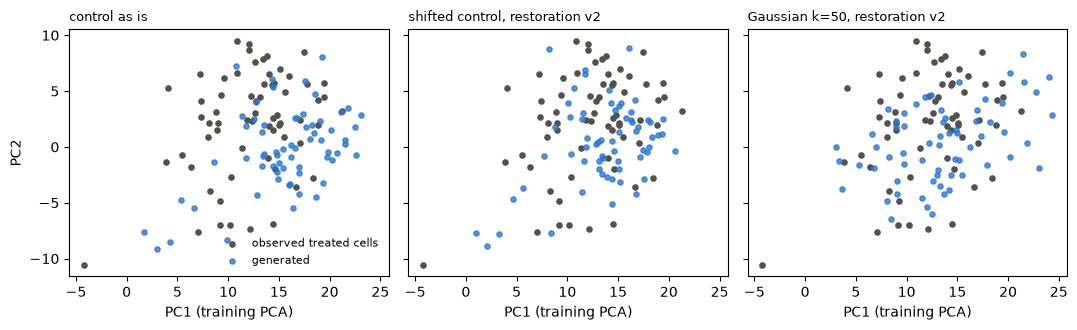

In [5]:
import matplotlib.pyplot as plt
P = lambda X: S.pca(X / S.sd).numpy()
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4), sharex=True, sharey=True)
for a, (name, X) in zip(ax, [("control as is", C), ("shifted control, restoration v2", pops["shifted control, restoration v2"]),
                             ("Gaussian k=50, restoration v2", pops["Gaussian k=50, restoration v2"])]):
    pt, pg = P(T), P(X)
    a.scatter(pt[:, 0], pt[:, 1], s=14, c="#52514e", label="observed treated cells")
    a.scatter(pg[:, 0], pg[:, 1], s=14, c="#2a78d6", alpha=0.8, label="generated")
    a.set_title(name, fontsize=9, loc="left"); a.set_xlabel("PC1 (training PCA)")
ax[0].set_ylabel("PC2"); ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()